In [ ]:

import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("Available GPU:", tf.config.list_physical_devices("GPU"))


TensorFlow version: 2.21.0
Available GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
!pip install -q kagglehub
import kagglehub

path = kagglehub.dataset_download(
    "tawsifurrahman/covid19-radiography-database"
)

print("Dataset path:", path)

Using Colab cache for faster access to the 'covid19-radiography-database' dataset.
Dataset path: /kaggle/input/covid19-radiography-database


In [ ]:
import os

print("Main folders:")

for item in os.listdir(path):
    print(item)

Main folders:
COVID-19_Radiography_Dataset


In [ ]:

import os

for root, dirs, files in os.walk(dataset_path):
    print("Folder:", root)
    print("Subfolders:", dirs[:5])
    print("Files:", files[:5])
    print("-" * 50)

    # Limit output so we don't print thousands of folders
    if root.count(os.sep) - dataset_path.count(os.sep) >= 2:
        dirs[:] = []


Folder: /root/.cache/kagglehub/datasets/khanfashee/nih-chest-x-ray-14-224x224-resized/versions/3
Subfolders: ['images-224']
Files: ['Data_Entry_2017.csv', 'BBox_List_2017_Official_NIH.csv', 'train_val_list_NIH.txt', 'test_list_NIH.txt', 'pretrained_model.h5']
--------------------------------------------------
Folder: /root/.cache/kagglehub/datasets/khanfashee/nih-chest-x-ray-14-224x224-resized/versions/3/images-224
Subfolders: ['images-224']
Files: []
--------------------------------------------------
Folder: /root/.cache/kagglehub/datasets/khanfashee/nih-chest-x-ray-14-224x224-resized/versions/3/images-224/images-224
Subfolders: []
Files: ['00009067_001.png', '00018766_008.png', '00028066_002.png', '00005520_007.png', '00008691_009.png']
--------------------------------------------------


In [ ]:

import os

dataset_path = os.path.join(path, "COVID-19_Radiography_Dataset")

classes = ["Normal", "Lung_Opacity", "Viral Pneumonia", "COVID"]

for category in classes:
    image_folder = os.path.join(dataset_path, category, "images")

    images = [
        f for f in os.listdir(image_folder)
        if f.lower().endswith((".png", ".jpg", ".jpeg"))
    ]

    print(f"{category}: {len(images)} images")


Normal: 10192 images
Lung_Opacity: 6012 images
Viral Pneumonia: 1345 images
COVID: 3616 images


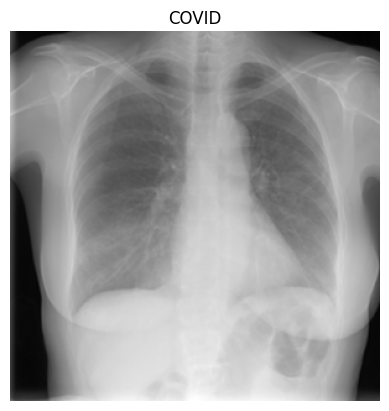

In [ ]:

import matplotlib.pyplot as plt
from PIL import Image

category = "COVID"
image_folder = os.path.join(dataset_path, category, "images")

image_file = next(
    f for f in os.listdir(image_folder)
    if f.lower().endswith((".png", ".jpg", ".jpeg"))
)

img = Image.open(os.path.join(image_folder, image_file))

plt.imshow(img, cmap="gray")
plt.title(category)
plt.axis("off")
plt.show()


In [ ]:

import os

dataset_path = os.path.join(path, "COVID-19_Radiography_Dataset")

classes = ["Normal", "COVID", "Lung_Opacity", "Viral Pneumonia"]

counts = {}

for category in classes:
    folder = os.path.join(dataset_path, category, "images")
    counts[category] = sum(
        f.lower().endswith((".png", ".jpg", ".jpeg"))
        for f in os.listdir(folder)
    )

print("Class distribution:")
for category, count in counts.items():
    print(f"{category}: {count}")

print("\nLargest-to-smallest class ratio:",
      round(max(counts.values()) / min(counts.values()), 2))


Class distribution:
Normal: 10192
COVID: 3616
Lung_Opacity: 6012
Viral Pneumonia: 1345

Largest-to-smallest class ratio: 7.58


In [ ]:

import os
import pandas as pd
from sklearn.model_selection import train_test_split

dataset_path = os.path.join(
    path, "COVID-19_Radiography_Dataset"
)

classes = [
    "Normal",
    "COVID",
    "Lung_Opacity",
    "Viral Pneumonia"
]

image_paths = []
labels = []

for label, category in enumerate(classes):
    folder = os.path.join(dataset_path, category, "images")

    for filename in os.listdir(folder):
        if filename.lower().endswith((".png", ".jpg", ".jpeg")):
            image_paths.append(os.path.join(folder, filename))
            labels.append(label)

df = pd.DataFrame({
    "image_path": image_paths,
    "label": labels
})

train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    stratify=df["label"],
    random_state=42
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=42
)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

print("\nTraining distribution:")
print(train_df["label"].value_counts().sort_index())


Training images: 14815
Validation images: 3175
Testing images: 3175

Training distribution:
label
0    7134
1    2531
2    4208
3     942
Name: count, dtype: int64


In [ ]:

from sklearn.utils.class_weight import compute_class_weight
import numpy as np

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(train_df["label"]),
    y=train_df["label"]
)

class_weights = dict(enumerate(class_weights))

print("Class weights:")
for label, weight in class_weights.items():
    print(f"{classes[label]}: {weight:.3f}")


Class weights:
Normal: 0.519
COVID: 1.463
Lung_Opacity: 0.880
Viral Pneumonia: 3.932


In [ ]:

import tensorflow as tf
from tensorflow.keras.applications.resnet50 import preprocess_input

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

def load_image(image_path, label):
    image = tf.io.read_file(image_path)
    image = tf.io.decode_png(image, channels=3)
    image = tf.image.resize(image, IMG_SIZE)
    image = preprocess_input(image)
    return image, label

def create_dataset(dataframe, training=False):
    ds = tf.data.Dataset.from_tensor_slices((
        dataframe["image_path"].values,
        dataframe["label"].values
    ))

    if training:
        ds = ds.shuffle(
            buffer_size=min(len(dataframe), 2000),
            seed=42
        )

    ds = ds.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(tf.data.AUTOTUNE)

    return ds

train_ds = create_dataset(train_df, training=True)
val_ds = create_dataset(val_df)
test_ds = create_dataset(test_df)

print("Image pipeline created successfully!")
print("Number of training batches:", len(train_ds))


Image pipeline created successfully!
Number of training batches: 463


In [ ]:

from tensorflow.keras.applications import ResNet50
from tensorflow.keras import layers, models

base_model = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(4, activation="softmax")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         8,196 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,595,908 (90.01 MB)

 Trainable params: 8,196 (32.02 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [ ]:

from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

callbacks = [
    ModelCheckpoint(
        "best_resnet50.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    class_weight=class_weights,
    callbacks=callbacks
)


Epoch 1/10
463/463 ━━━━━━━━━━━━━━━━━━━━ 0s 198ms/step - accuracy: 0.6604 - loss: 0.7612
Epoch 1: val_loss improved from None to 0.39498, saving model to best_resnet50.keras

Epoch 1: finished saving model to best_resnet50.keras
463/463 ━━━━━━━━━━━━━━━━━━━━ 132s 257ms/step - accuracy: 0.7516 - loss: 0.5379 - val_accuracy: 0.8463 - val_loss: 0.3950
Epoch 2/10
463/463 ━━━━━━━━━━━━━━━━━━━━ 0s 115ms/step - accuracy: 0.8253 - loss: 0.3625
Epoch 2: val_loss improved from 0.39498 to 0.33647, saving model to best_resnet50.keras

Epoch 2: finished saving model to best_resnet50.keras
463/463 ━━━━━━━━━━━━━━━━━━━━ 66s 142ms/step - accuracy: 0.8330 - loss: 0.3517 - val_accuracy: 0.8728 - val_loss: 0.3365
Epoch 3/10
463/463 ━━━━━━━━━━━━━━━━━━━━ 0s 115ms/step - accuracy: 0.8469 - loss: 0.3285
Epoch 3: val_loss improved from 0.33647 to 0.31689, saving model to best_resnet50.keras

Epoch 3: finished saving model to best_resnet50.keras
463/463 ━━━━━━━━━━━━━━━━━━━━ 91s 162ms/step - accuracy: 0.8476 - loss

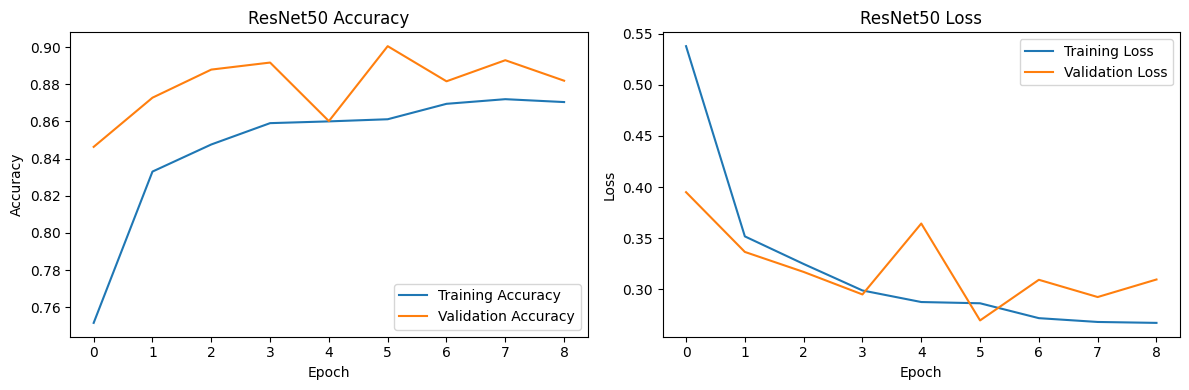

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("ResNet50 Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("ResNet50 Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()


100/100 ━━━━━━━━━━━━━━━━━━━━ 18s 176ms/step - accuracy: 0.9055 - loss: 0.2718

Test Accuracy: 90.55%
Test Loss: 0.2718
100/100 ━━━━━━━━━━━━━━━━━━━━ 22s 177ms/step

Classification Report:
                 precision    recall  f1-score   support

         Normal     0.9091    0.9294    0.9191      1529
          COVID     0.9147    0.8708    0.8922       542
   Lung_Opacity     0.8820    0.8780    0.8800       902
Viral Pneumonia     0.9596    0.9406    0.9500       202

       accuracy                         0.9055      3175
      macro avg     0.9164    0.9047    0.9103      3175
   weighted avg     0.9056    0.9055    0.9054      3175



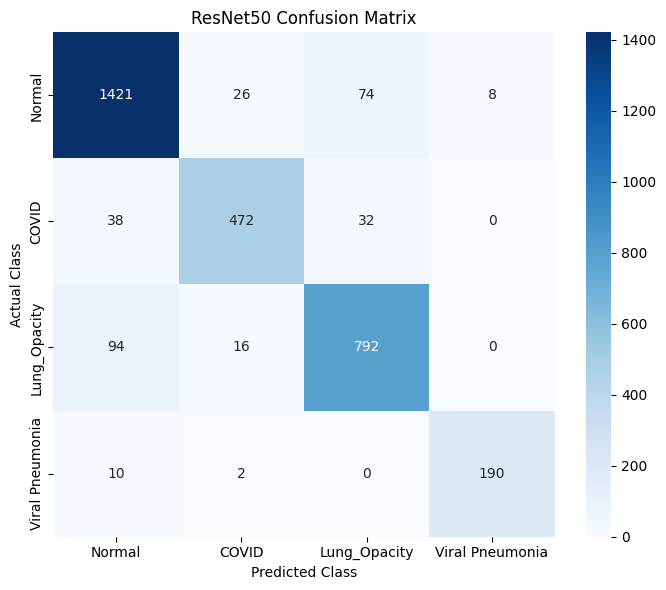

In [ ]:

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Evaluate the restored best model
test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)

print(f"\nTest Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

# Generate predictions
y_true = np.concatenate([
    labels.numpy() for _, labels in test_ds
])

y_prob = model.predict(test_ds, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

# Per-class metrics
print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3],
    target_names=classes,
    digits=4,
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2, 3])

plt.figure(figsize=(7, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes
)
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("ResNet50 Confusion Matrix")
plt.tight_layout()
plt.show()


In [ ]:
model.save("chest_xray_resnet50.keras")
print("Model saved successfully!")

Model saved successfully!


Saving Screenshot 2026-10-20 155036.png to Screenshot 2026-10-20 155036.png


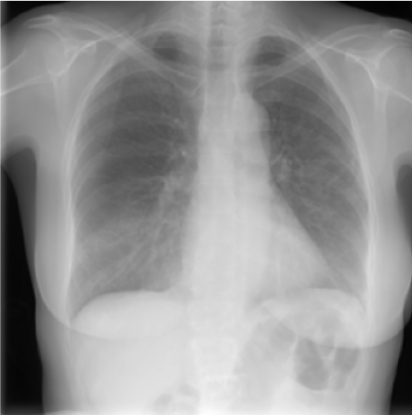

In [ ]:
from google.colab import files
from IPython.display import display
from PIL import Image
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# Upload an X-ray image
uploaded = files.upload()

# Get the uploaded image filename
image_path = next(iter(uploaded))

# Display the image
img = Image.open(image_path).convert("RGB")
display(img)

In [ ]:
from tensorflow.keras.applications.resnet50 import preprocess_input

# Class names in the same order used during training
classes = ["Normal", "COVID", "Lung_Opacity", "Viral Pneumonia"]

# Resize the image to the model's input size
img = Image.open(image_path).convert("RGB")
img = img.resize((224, 224))

# Convert image to an array
img_array = np.array(img, dtype=np.float32)

# Preprocess the image
img_array = np.expand_dims(img_array, axis=0)
img_array = preprocess_input(img_array)

# Predict
predictions = model.predict(img_array, verbose=0)

# Get predicted class and confidence
predicted_index = np.argmax(predictions[0])
predicted_class = classes[predicted_index]
confidence = predictions[0][predicted_index] * 100

print("Predicted Class:", predicted_class)
print(f"Model Confidence: {confidence:.2f}%")

Predicted Class: COVID
Model Confidence: 83.76%


In [ ]:
for i, class_name in enumerate(classes):
    print(f"{class_name}: {predictions[0][i] * 100:.2f}%")

Normal: 15.77%
COVID: 83.76%
Lung_Opacity: 0.48%
Viral Pneumonia: 0.00%


In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("khanfashee/nih-chest-x-ray-14-224x224-resized")

print("Path to dataset files:", path)

100%|██████████| 2.30G/2.30G [00:32<00:00, 75.5MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/khanfashee/nih-chest-x-ray-14-224x224-resized/versions/3


In [ ]:
import os

print("Dataset path:", path)

for root, dirs, files in os.walk(path):
    depth = root.replace(path, "").count(os.sep)

    if depth <= 2:
        print("\nFolder:", root)

        for filename in files[:10]:
            print("  ", filename)

        if len(files) > 10:
            print("  ... and more files")

Dataset path: /root/.cache/kagglehub/datasets/khanfashee/nih-chest-x-ray-14-224x224-resized/versions/3

Folder: /root/.cache/kagglehub/datasets/khanfashee/nih-chest-x-ray-14-224x224-resized/versions/3
   Data_Entry_2017.csv
   BBox_List_2017_Official_NIH.csv
   train_val_list_NIH.txt
   test_list_NIH.txt
   pretrained_model.h5

Folder: /root/.cache/kagglehub/datasets/khanfashee/nih-chest-x-ray-14-224x224-resized/versions/3/images-224

Folder: /root/.cache/kagglehub/datasets/khanfashee/nih-chest-x-ray-14-224x224-resized/versions/3/images-224/images-224
   00009067_001.png
   00018766_008.png
   00028066_002.png
   00005520_007.png
   00008691_009.png
   00005664_000.png
   00008922_013.png
   00026312_001.png
   00017747_052.png
   00015160_022.png
  ... and more files


In [ ]:
import glob

csv_files = glob.glob(
    os.path.join(path, "**", "*.csv"),
    recursive=True
)

print("CSV files found:", len(csv_files))

for file in csv_files:
    print(file)

CSV files found: 2
/root/.cache/kagglehub/datasets/khanfashee/nih-chest-x-ray-14-224x224-resized/versions/3/Data_Entry_2017.csv
/root/.cache/kagglehub/datasets/khanfashee/nih-chest-x-ray-14-224x224-resized/versions/3/BBox_List_2017_Official_NIH.csv


In [ ]:
import pandas as pd

for file in csv_files:
    print("\nFile:", file)

    try:
        temp_df = pd.read_csv(file, nrows=5)
        print("Columns:", temp_df.columns.tolist())
        display(temp_df.head(3))
    except Exception as e:
        print("Could not read:", e)


File: /root/.cache/kagglehub/datasets/khanfashee/nih-chest-x-ray-14-224x224-resized/versions/3/Data_Entry_2017.csv
Columns: ['Image Index', 'Finding Labels', 'Follow-up #', 'Patient ID', 'Patient Age', 'Patient Gender', 'View Position', 'OriginalImage[Width', 'Height]', 'OriginalImagePixelSpacing[x', 'y]', 'Unnamed: 11']


,Image Index,Finding Labels,Follow-up #,Patient ID,Patient Age,Patient Gender,View Position,OriginalImage[Width,Height],OriginalImagePixelSpacing[x,y],Unnamed: 11
0,00000001_000.png,Cardiomegaly,0,1,058Y,M,PA,2682,2749,0.143,0.143,NaN
1,00000001_001.png,Cardiomegaly|Emphysema,1,1,058Y,M,PA,2894,2729,0.143,0.143,NaN
2,00000001_002.png,Cardiomegaly|Effusion,2,1,058Y,M,PA,2500,2048,0.168,0.168,NaN



File: /root/.cache/kagglehub/datasets/khanfashee/nih-chest-x-ray-14-224x224-resized/versions/3/BBox_List_2017_Official_NIH.csv
Columns: ['Image Index', 'Finding Label', 'Bbox [x', 'y', 'w', 'h]', 'Unnamed: 6', 'Unnamed: 7', 'Unnamed: 8']


,Image Index,Finding Label,Bbox [x,y,w,h],Unnamed: 6,Unnamed: 7,Unnamed: 8
0,00013118_008.png,Atelectasis,225.084746,547.019217,86.779661,79.186441,NaN,NaN,NaN
1,00014716_007.png,Atelectasis,686.101695,131.543498,185.491525,313.491525,NaN,NaN,NaN
2,00029817_009.png,Atelectasis,221.830508,317.053115,155.118644,216.949153,NaN,NaN,NaN


In [ ]:
import os
import glob
import pandas as pd

print("DATASET FOLDERS")
for root, dirs, files in os.walk(path):
    depth = root.replace(path, "").count(os.sep)
    if depth <= 2:
        print(root, "| files:", len(os.listdir(root)))

print("\nCSV FILES")
for file in glob.glob(os.path.join(path, "**", "*.csv"), recursive=True):
    print("\nFile:", file)
    df_sample = pd.read_csv(file, nrows=3)
    print("Columns:", df_sample.columns.tolist())
    display(df_sample)

DATASET FOLDERS
/root/.cache/kagglehub/datasets/khanfashee/nih-chest-x-ray-14-224x224-resized/versions/3 | files: 6
/root/.cache/kagglehub/datasets/khanfashee/nih-chest-x-ray-14-224x224-resized/versions/3/images-224 | files: 1
/root/.cache/kagglehub/datasets/khanfashee/nih-chest-x-ray-14-224x224-resized/versions/3/images-224/images-224 | files: 112120

CSV FILES

File: /root/.cache/kagglehub/datasets/khanfashee/nih-chest-x-ray-14-224x224-resized/versions/3/Data_Entry_2017.csv
Columns: ['Image Index', 'Finding Labels', 'Follow-up #', 'Patient ID', 'Patient Age', 'Patient Gender', 'View Position', 'OriginalImage[Width', 'Height]', 'OriginalImagePixelSpacing[x', 'y]', 'Unnamed: 11']


,Image Index,Finding Labels,Follow-up #,Patient ID,Patient Age,Patient Gender,View Position,OriginalImage[Width,Height],OriginalImagePixelSpacing[x,y],Unnamed: 11
0,00000001_000.png,Cardiomegaly,0,1,058Y,M,PA,2682,2749,0.143,0.143,NaN
1,00000001_001.png,Cardiomegaly|Emphysema,1,1,058Y,M,PA,2894,2729,0.143,0.143,NaN
2,00000001_002.png,Cardiomegaly|Effusion,2,1,058Y,M,PA,2500,2048,0.168,0.168,NaN



File: /root/.cache/kagglehub/datasets/khanfashee/nih-chest-x-ray-14-224x224-resized/versions/3/BBox_List_2017_Official_NIH.csv
Columns: ['Image Index', 'Finding Label', 'Bbox [x', 'y', 'w', 'h]', 'Unnamed: 6', 'Unnamed: 7', 'Unnamed: 8']


,Image Index,Finding Label,Bbox [x,y,w,h],Unnamed: 6,Unnamed: 7,Unnamed: 8
0,00013118_008.png,Atelectasis,225.084746,547.019217,86.779661,79.186441,NaN,NaN,NaN
1,00014716_007.png,Atelectasis,686.101695,131.543498,185.491525,313.491525,NaN,NaN,NaN
2,00029817_009.png,Atelectasis,221.830508,317.053115,155.118644,216.949153,NaN,NaN,NaN


In [ ]:
import os
import pandas as pd
import numpy as np

# Main dataset folder
dataset_path = path

# Folder containing the resized images
images_dir = os.path.join(
    dataset_path, "images-224", "images-224"
)

# The 14 disease labels
disease_classes = [
    "Atelectasis",
    "Cardiomegaly",
    "Effusion",
    "Infiltration",
    "Mass",
    "Nodule",
    "Pneumonia",
    "Pneumothorax",
    "Consolidation",
    "Edema",
    "Emphysema",
    "Fibrosis",
    "Pleural_Thickening",
    "Hernia"
]

# Load the metadata
csv_path = os.path.join(dataset_path, "Data_Entry_2017.csv")
df = pd.read_csv(csv_path)

print("Number of metadata rows:", len(df))
print("Number of disease classes:", len(disease_classes))
print("Images folder exists:", os.path.isdir(images_dir))
print("Example image exists:", os.path.isfile(
    os.path.join(images_dir, df["Image Index"].iloc[0])
))

Number of metadata rows: 112120
Number of disease classes: 14
Images folder exists: True
Example image exists: True


In [ ]:
# Keep the columns needed for classification
df = df[
    ["Image Index", "Finding Labels", "Patient ID"]
].copy()

# Create one binary column for each disease
for disease in disease_classes:
    df[disease] = df["Finding Labels"].apply(
        lambda labels: int(disease in labels.split("|"))
    )

# Create the full image paths
df["image_path"] = df["Image Index"].apply(
    lambda name: os.path.join(images_dir, name)
)

# Remove rows whose image files are missing
df = df[df["image_path"].map(os.path.isfile)].copy()

df = df.reset_index(drop=True)

print("Usable images:", len(df))
print("Unique patients:", df["Patient ID"].nunique())

print("\nFirst few image labels:")
display(df[["Image Index"] + disease_classes[:4]].head())

Usable images: 112120
Unique patients: 30805

First few image labels:


,Image Index,Atelectasis,Cardiomegaly,Effusion,Infiltration
0,00000001_000.png,0,1,0,0
1,00000001_001.png,0,1,0,0
2,00000001_002.png,0,1,1,0
3,00000002_000.png,0,0,0,0
4,00000003_000.png,0,0,0,0


In [ ]:
disease_counts = df[disease_classes].sum().sort_values(
    ascending=False
)

print(disease_counts)

Infiltration          19870
Effusion              13307
Atelectasis           11535
Nodule                 6323
Mass                   5746
Pneumothorax           5298
Consolidation          4667
Pleural_Thickening     3385
Cardiomegaly           2772
Emphysema              2516
Edema                  2303
Fibrosis               1686
Pneumonia              1353
Hernia                  227
dtype: int64


In [ ]:
from sklearn.model_selection import GroupShuffleSplit

# First: reserve 15% of patients for testing
split1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.15,
    random_state=42
)

train_val_idx, test_idx = next(
    split1.split(df, groups=df["Patient ID"])
)

train_val_df = df.iloc[train_val_idx].copy()
test_df = df.iloc[test_idx].copy()

# Second: reserve approximately 15% of all patients for validation
# (15/85 = 0.1765)
split2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.1765,
    random_state=42
)

train_idx, val_idx = next(
    split2.split(
        train_val_df,
        groups=train_val_df["Patient ID"]
    )
)

train_df = train_val_df.iloc[train_idx].copy()
val_df = train_val_df.iloc[val_idx].copy()

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

# Verify that no patient appears in multiple splits
train_patients = set(train_df["Patient ID"])
val_patients = set(val_df["Patient ID"])
test_patients = set(test_df["Patient ID"])

print("\nPatient overlap:")
print("Train/validation:", len(train_patients & val_patients))
print("Train/test:", len(train_patients & test_patients))
print("Validation/test:", len(val_patients & test_patients))

Training images: 78298
Validation images: 17098
Testing images: 16724

Patient overlap:
Train/validation: 0
Train/test: 0
Validation/test: 0


In [ ]:
import tensorflow as tf
from tensorflow.keras.applications.resnet50 import preprocess_input

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

def load_image(image_path, labels):
    image = tf.io.read_file(image_path)
    image = tf.io.decode_png(image, channels=3)
    image = tf.image.resize(image, IMG_SIZE)
    image = preprocess_input(image)

    return image, labels

def create_dataset(dataframe, training=False):
    image_paths = dataframe["image_path"].values

    labels = dataframe[disease_classes].values.astype("float32")

    ds = tf.data.Dataset.from_tensor_slices(
        (image_paths, labels)
    )

    if training:
        ds = ds.shuffle(
            buffer_size=min(len(dataframe), 5000),
            seed=42
        )

    ds = ds.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(tf.data.AUTOTUNE)

    return ds

train_ds = create_dataset(train_df, training=True)
val_ds = create_dataset(val_df)
test_ds = create_dataset(test_df)

print("Datasets created successfully!")

Datasets created successfully!


In [ ]:
for images, labels in train_ds.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("First image labels:", labels[0].numpy())

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32, 14)
First image labels: [0. 1. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


In [ ]:
from tensorflow.keras.applications import ResNet50
from tensorflow.keras import layers, models

# Load pretrained ResNet50
base_model_nih = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze pretrained layers initially
base_model_nih.trainable = False

# Build the 14-label classifier
nih_model = models.Sequential([
    base_model_nih,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(14, activation="sigmoid")
])

# Compile for multi-label classification
nih_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="binary_accuracy")
    ]
)

nih_model.summary()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 14)             │        28,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,616,398 (90.09 MB)

 Trainable params: 28,686 (112.05 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

nih_callbacks = [
    ModelCheckpoint(
        "best_nih_resnet50.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True,
        verbose=1
    )
]

nih_history = nih_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=nih_callbacks
)

Epoch 1/5
2447/2447 ━━━━━━━━━━━━━━━━━━━━ 0s 96ms/step - binary_accuracy: 0.9482 - loss: 0.1814
Epoch 1: val_loss improved from None to 0.17269, saving model to best_nih_resnet50.keras

Epoch 1: finished saving model to best_nih_resnet50.keras
2447/2447 ━━━━━━━━━━━━━━━━━━━━ 334s 131ms/step - binary_accuracy: 0.9461 - loss: 0.1792 - val_binary_accuracy: 0.9486 - val_loss: 0.1727
Epoch 2/5
2447/2447 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step - binary_accuracy: 0.9512 - loss: 0.1654
Epoch 2: val_loss improved from 0.17269 to 0.16937, saving model to best_nih_resnet50.keras

Epoch 2: finished saving model to best_nih_resnet50.keras
2447/2447 ━━━━━━━━━━━━━━━━━━━━ 317s 129ms/step - binary_accuracy: 0.9470 - loss: 0.1721 - val_binary_accuracy: 0.9489 - val_loss: 0.1694
Epoch 3/5
2447/2447 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step - binary_accuracy: 0.9511 - loss: 0.1642
Epoch 3: val_loss improved from 0.16937 to 0.16799, saving model to best_nih_resnet50.keras

Epoch 3: finished saving model to best_nih_resnet

In [ ]:
print("Model loaded:", "nih_model" in globals())
print("Test dataset ready:", "test_ds" in globals())
print("Test dataframe ready:", "test_df" in globals())

Model loaded: True
Test dataset ready: True
Test dataframe ready: True


In [ ]:
import numpy as np
from sklearn.metrics import classification_report, roc_auc_score

# Get actual labels and predicted probabilities
y_true = np.concatenate([labels.numpy() for images, labels in test_ds], axis=0)
y_prob = nih_model.predict(test_ds)

# Convert probabilities to binary predictions
y_pred = (y_prob >= 0.5).astype(int)

# Precision, recall and F1-score for each disease
print(classification_report(
    y_true,
    y_pred,
    target_names=disease_classes,
    zero_division=0
))

# ROC-AUC for each disease
for i, disease in enumerate(disease_classes):
    try:
        auc = roc_auc_score(y_true[:, i], y_prob[:, i])
        print(f"{disease}: AUC = {auc:.4f}")
    except ValueError:
        print(f"{disease}: AUC could not be calculated")

523/523 ━━━━━━━━━━━━━━━━━━━━ 60s 108ms/step
                    precision    recall  f1-score   support

       Atelectasis       0.00      0.00      0.00      1688
      Cardiomegaly       0.00      0.00      0.00       426
          Effusion       0.54      0.07      0.12      1934
      Infiltration       0.39      0.01      0.01      2939
              Mass       0.56      0.01      0.01       828
            Nodule       0.40      0.01      0.02       930
         Pneumonia       0.00      0.00      0.00       210
      Pneumothorax       0.43      0.00      0.01       809
     Consolidation       0.00      0.00      0.00       692
             Edema       0.40      0.01      0.01       333
         Emphysema       1.00      0.01      0.02       417
          Fibrosis       0.00      0.00      0.00       281
Pleural_Thickening       0.00      0.00      0.00       497
            Hernia       0.00      0.00      0.00        43

         micro avg       0.50      0.01      0.03     

In [ ]:
import numpy as np

print("Minimum probability:", np.min(y_prob))
print("Maximum probability:", np.max(y_prob))
print("Mean probability:", np.mean(y_prob))

print("\nPositive predictions per disease:")
for i, disease in enumerate(disease_classes):
    count = np.sum(y_pred[:, i])
    print(f"{disease}: {count}")

Minimum probability: 8.005088e-09
Maximum probability: 0.96967363
Mean probability: 0.04195919

Positive predictions per disease:
Atelectasis: 10
Cardiomegaly: 3
Effusion: 251
Infiltration: 38
Mass: 9
Nodule: 20
Pneumonia: 0
Pneumothorax: 7
Consolidation: 0
Edema: 5
Emphysema: 5
Fibrosis: 0
Pleural_Thickening: 0
Hernia: 0


In [ ]:
import numpy as np
from sklearn.metrics import precision_recall_curve

# True validation labels and predicted probabilities
y_val_true = np.concatenate(
    [labels.numpy() for images, labels in val_ds], axis=0
)

y_val_prob = nih_model.predict(val_ds)

# Find the best F1 threshold for each disease
best_thresholds = []

for i, disease in enumerate(disease_classes):
    precision, recall, thresholds = precision_recall_curve(
        y_val_true[:, i], y_val_prob[:, i]
    )

    # F1 for each threshold
    f1 = 2 * precision[:-1] * recall[:-1] / (
        precision[:-1] + recall[:-1] + 1e-8
    )

    best_idx = np.argmax(f1)
    threshold = thresholds[best_idx]
    best_thresholds.append(threshold)

    print(
        f"{disease}: threshold={threshold:.4f}, "
        f"validation F1={f1[best_idx]:.4f}"
    )

best_thresholds = np.array(best_thresholds)

535/535 ━━━━━━━━━━━━━━━━━━━━ 54s 102ms/step
Atelectasis: threshold=0.1309, validation F1=0.3102
Cardiomegaly: threshold=0.0887, validation F1=0.1595
Effusion: threshold=0.1475, validation F1=0.4163
Infiltration: threshold=0.1364, validation F1=0.3647
Mass: threshold=0.0858, validation F1=0.1847
Nodule: threshold=0.1229, validation F1=0.1785
Pneumonia: threshold=0.0351, validation F1=0.0503
Pneumothorax: threshold=0.0706, validation F1=0.2790
Consolidation: threshold=0.0901, validation F1=0.1772
Edema: threshold=0.0619, validation F1=0.1778
Emphysema: threshold=0.0395, validation F1=0.1917
Fibrosis: threshold=0.0109, validation F1=0.1348
Pleural_Thickening: threshold=0.0485, validation F1=0.1229
Hernia: threshold=0.0135, validation F1=0.1053


In [ ]:
from sklearn.metrics import classification_report

y_test_pred_tuned = (
    y_prob >= best_thresholds.reshape(1, -1)
).astype(int)

print(classification_report(
    y_true,
    y_test_pred_tuned,
    target_names=disease_classes,
    zero_division=0
))

                    precision    recall  f1-score   support

       Atelectasis       0.22      0.50      0.31      1688
      Cardiomegaly       0.09      0.30      0.14       426
          Effusion       0.30      0.62      0.41      1934
      Infiltration       0.26      0.55      0.35      2939
              Mass       0.15      0.29      0.20       828
            Nodule       0.14      0.20      0.17       930
         Pneumonia       0.05      0.06      0.05       210
      Pneumothorax       0.25      0.36      0.30       809
     Consolidation       0.11      0.49      0.18       692
             Edema       0.10      0.50      0.17       333
         Emphysema       0.21      0.25      0.23       417
          Fibrosis       0.10      0.09      0.09       281
Pleural_Thickening       0.07      0.31      0.12       497
            Hernia       0.11      0.16      0.13        43

         micro avg       0.19      0.44      0.27     12027
         macro avg       0.15      0.3

In [ ]:
import numpy as np
import os

# Save the trained model
nih_model.save("/content/nih_resnet50_final.keras")

# Save the 14 tuned thresholds
np.save("/content/nih_best_thresholds.npy", best_thresholds)

print("Model saved:", os.path.exists("/content/nih_resnet50_final.keras"))
print("Thresholds saved:", os.path.exists("/content/nih_best_thresholds.npy"))

Model saved: True
Thresholds saved: True


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving Screenshot 2026-10-20 155036.png to Screenshot 2026-10-20 155036.png


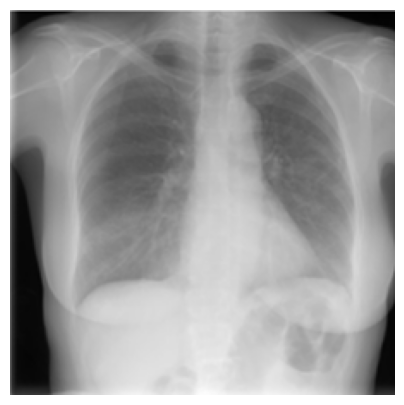

Atelectasis: 4.64% — Below threshold
Cardiomegaly: 1.54% — Below threshold
Effusion: 3.25% — Below threshold
Infiltration: 10.41% — Below threshold
Mass: 3.14% — Below threshold
Nodule: 6.81% — Below threshold
Pneumonia: 0.17% — Below threshold
Pneumothorax: 1.48% — Below threshold
Consolidation: 2.49% — Below threshold
Edema: 0.13% — Below threshold
Emphysema: 0.26% — Below threshold
Fibrosis: 0.59% — Below threshold
Pleural_Thickening: 1.37% — Below threshold
Hernia: 0.01% — Below threshold


In [ ]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.applications.resnet50 import preprocess_input
from PIL import Image

# Get the uploaded filename
filename = next(iter(uploaded))

# Load and preprocess the image
img = Image.open(filename).convert("RGB").resize((224, 224))
img_array = np.array(img, dtype=np.float32)
img_array = preprocess_input(img_array)
img_array = np.expand_dims(img_array, axis=0)

# Predict probabilities
probabilities = nih_model.predict(img_array, verbose=0)[0]

# Display image
plt.figure(figsize=(5, 5))
plt.imshow(img)
plt.axis("off")
plt.show()

# Display predictions
for i, disease in enumerate(disease_classes):
    status = "Above threshold" if probabilities[i] >= best_thresholds[i] else "Below threshold"
    print(f"{disease}: {probabilities[i]:.2%} — {status}")

In [ ]:
import os

print("COVID model file exists:",
      os.path.exists("/content/best_resnet50.keras"))

print("Alternative model file exists:",
      os.path.exists("/content/chest_xray_resnet50.keras"))

COVID model file exists: True
Alternative model file exists: True


In [ ]:
import tensorflow as tf

covid_model = tf.keras.models.load_model(
    "/content/best_resnet50.keras"
)

print("COVID model loaded successfully!")
covid_model.summary()

COVID model loaded successfully!


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         8,196 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,612,302 (90.07 MB)

 Trainable params: 8,196 (32.02 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

 Optimizer params: 16,394 (64.04 KB)

In [ ]:

import os

# Check the NIH dataset
nih_path = (
    "/root/.cache/kagglehub/datasets/"
    "khanfashee/nih-chest-x-ray-14-224x224-resized/versions/3"
)

nih_images = os.path.join(nih_path, "images-224", "images-224")
nih_csv = os.path.join(nih_path, "Data_Entry_2017.csv")

print("NIH images available:", os.path.isdir(nih_images))
print("NIH labels available:", os.path.isfile(nih_csv))

# Search the cached Kaggle datasets for the COVID dataset
cache_root = "/root/.cache/kagglehub/datasets"
covid_matches = []

for root, dirs, files in os.walk(cache_root):
    dirs[:] = [d for d in dirs if d != ".git"]

    if "COVID-19_Radiography_Dataset" in dirs:
        covid_matches.append(
            os.path.join(root, "COVID-19_Radiography_Dataset")
        )

print("\nCOVID dataset folders found:")
for folder in covid_matches:
    print(folder)


NIH images available: True
NIH labels available: True

COVID dataset folders found:


In [ ]:

print("COVID model in memory:", "covid_model" in globals())
print("NIH model in memory:", "nih_model" in globals())

print("COVID dataset path in memory:", "path" in globals())
print("COVID dataframe in memory:", "df_covid" in globals())
print("NIH dataframe in memory:", "df" in globals())


COVID model in memory: True
NIH model in memory: True
COVID dataset path in memory: True
COVID dataframe in memory: False
NIH dataframe in memory: True


In [ ]:

print("Current path variable:", path)
print("Does this path exist?", os.path.exists(path))

if os.path.exists(path):
    print("\nFolders inside the path:")
    print(os.listdir(path)[:20])


Current path variable: /kaggle/input/covid19-radiography-database
Does this path exist? True

Folders inside the path:
['COVID-19_Radiography_Dataset']


In [ ]:

import os

covid_dataset_path = os.path.join(
    path, "COVID-19_Radiography_Dataset"
)

print("Dataset folder:", covid_dataset_path)
print("\nAvailable folders:")

for folder in os.listdir(covid_dataset_path):
    folder_path = os.path.join(covid_dataset_path, folder)

    if os.path.isdir(folder_path):
        print(f"{folder}: {len(os.listdir(folder_path))} files")


Dataset folder: /kaggle/input/covid19-radiography-database/COVID-19_Radiography_Dataset

Available folders:
Normal: 2 files
Lung_Opacity: 2 files
Viral Pneumonia: 2 files
COVID: 2 files


In [ ]:

import os

for category in ["Normal", "COVID", "Lung_Opacity", "Viral Pneumonia"]:
    folder = os.path.join(covid_dataset_path, category)

    print(f"\n{category}:")
    for item in os.listdir(folder):
        item_path = os.path.join(folder, item)

        if os.path.isdir(item_path):
            print(f"  Folder: {item} — {len(os.listdir(item_path))} items")
        else:
            print(f"  File: {item}")



Normal:
  Folder: images — 10192 items
  Folder: masks — 10192 items

COVID:
  Folder: images — 3616 items
  Folder: masks — 3616 items

Lung_Opacity:
  Folder: images — 6012 items
  Folder: masks — 6012 items

Viral Pneumonia:
  Folder: images — 1345 items
  Folder: masks — 1345 items


In [ ]:

covid_classes = [
    "Normal",
    "COVID",
    "Lung_Opacity",
    "Viral Pneumonia"
]

nih_classes = [
    "Atelectasis", "Cardiomegaly", "Effusion", "Infiltration",
    "Mass", "Nodule", "Pneumonia", "Pneumothorax",
    "Consolidation", "Edema", "Emphysema", "Fibrosis",
    "Pleural_Thickening", "Hernia"
]

all_classes = covid_classes + nih_classes

print("Total output classes:", len(all_classes))
print("\nClass order:")
for i, name in enumerate(all_classes, start=1):
    print(f"{i}. {name}")

print("\nNIH label columns available:",
      all(col in df.columns for col in nih_classes))


Total output classes: 18

Class order:
1. Normal
2. COVID
3. Lung_Opacity
4. Viral Pneumonia
5. Atelectasis
6. Cardiomegaly
7. Effusion
8. Infiltration
9. Mass
10. Nodule
11. Pneumonia
12. Pneumothorax
13. Consolidation
14. Edema
15. Emphysema
16. Fibrosis
17. Pleural_Thickening
18. Hernia

NIH label columns available: False


In [ ]:

print("NIH dataframe shape:", df.shape)
print("\nAvailable columns:")
print(df.columns.tolist())

print("\nFirst 3 rows:")
print(df.head(3))


NIH dataframe shape: (21165, 2)

Available columns:
['image_path', 'label']

First 3 rows:
                                          image_path  label
0  /kaggle/input/covid19-radiography-database/COV...      0
1  /kaggle/input/covid19-radiography-database/COV...      0
2  /kaggle/input/covid19-radiography-database/COV...      0


In [ ]:

import os
import pandas as pd

# NIH dataset paths
nih_dataset_path = (
    "/root/.cache/kagglehub/datasets/"
    "khanfashee/nih-chest-x-ray-14-224x224-resized/versions/3"
)

nih_images_dir = os.path.join(
    nih_dataset_path, "images-224", "images-224"
)

nih_csv_path = os.path.join(
    nih_dataset_path, "Data_Entry_2017.csv"
)

# Read NIH metadata
nih_df = pd.read_csv(nih_csv_path)

nih_df = nih_df[
    ["Image Index", "Finding Labels", "Patient ID"]
].copy()

# Create the 14 disease labels
for disease in nih_classes:
    nih_df[disease] = nih_df["Finding Labels"].apply(
        lambda labels: int(disease in labels.split("|"))
    )

# Create image paths
nih_df["image_path"] = nih_df["Image Index"].apply(
    lambda name: os.path.join(nih_images_dir, name)
)

# Keep images that exist
nih_df = nih_df[
    nih_df["image_path"].map(os.path.isfile)
].reset_index(drop=True)

print("NIH dataframe shape:", nih_df.shape)
print("Number of disease classes:", len(nih_classes))
print("\nDisease columns available:",
      all(c in nih_df.columns for c in nih_classes))

print("\nFirst 3 rows:")
print(nih_df[["Image Index", *nih_classes[:3]]].head(3))


NIH dataframe shape: (112120, 18)
Number of disease classes: 14

Disease columns available: True

First 3 rows:
        Image Index  Atelectasis  Cardiomegaly  Effusion
0  00000001_000.png            0             1         0
1  00000001_001.png            0             1         0
2  00000001_002.png            0             1         1


In [ ]:

# Check the COVID dataframe without changing it
print("COVID dataframe shape:", df.shape)
print("\nSample image paths and labels:")
print(df[["image_path", "label"]].head(8).to_string(index=False))

# Derive the category from the image's folder path
for image_path in df["image_path"].head(8):
    parts = image_path.replace("\\", "/").split("/")
    print(parts[-3:], "->", image_path)


COVID dataframe shape: (21165, 2)

Sample image paths and labels:
                                                                                            image_path  label
  /kaggle/input/covid19-radiography-database/COVID-19_Radiography_Dataset/Normal/images/Normal-859.png      0
  /kaggle/input/covid19-radiography-database/COVID-19_Radiography_Dataset/Normal/images/Normal-158.png      0
/kaggle/input/covid19-radiography-database/COVID-19_Radiography_Dataset/Normal/images/Normal-10121.png      0
 /kaggle/input/covid19-radiography-database/COVID-19_Radiography_Dataset/Normal/images/Normal-1811.png      0
   /kaggle/input/covid19-radiography-database/COVID-19_Radiography_Dataset/Normal/images/Normal-97.png      0
 /kaggle/input/covid19-radiography-database/COVID-19_Radiography_Dataset/Normal/images/Normal-1088.png      0
 /kaggle/input/covid19-radiography-database/COVID-19_Radiography_Dataset/Normal/images/Normal-5663.png      0
 /kaggle/input/covid19-radiography-database/COVID-19_R

In [ ]:

import os
import pandas as pd

# Get the category from each image's folder path
covid_df = df[["image_path"]].copy()

covid_df["category"] = covid_df["image_path"].apply(
    lambda p: p.replace("\\", "/").split("/")[-3]
)

# Confirm the four classes and their counts
print(covid_df["category"].value_counts())

# Check that every category is valid
print("\nAll categories valid:",
      covid_df["category"].isin(covid_classes).all())

print("Total COVID dataset images:", len(covid_df))


category
Normal             10192
Lung_Opacity        6012
COVID               3616
Viral Pneumonia     1345
Name: count, dtype: int64

All categories valid: True
Total COVID dataset images: 21165


In [ ]:

import numpy as np
from sklearn.model_selection import train_test_split, GroupShuffleSplit

# The 18 output classes
all_classes = covid_classes + nih_classes
num_classes = len(all_classes)

print("Number of classes:", num_classes)
print(all_classes)

# COVID dataset: first 4 outputs are known
covid_df = covid_df.copy()
covid_df["category"] = covid_df["image_path"].apply(
    lambda p: p.replace("\\", "/").split("/")[-3]
)
covid_df = covid_df[covid_df["category"].isin(covid_classes)].copy()

covid_df["class_id"] = covid_df["category"].map(
    {name: i for i, name in enumerate(covid_classes)}
)

covid_train, covid_test = train_test_split(
    covid_df,
    test_size=0.2,
    random_state=42,
    stratify=covid_df["class_id"]
)

# NIH dataset: split by patient to reduce data leakage
splitter = GroupShuffleSplit(
    n_splits=1, test_size=0.2, random_state=42
)
nih_train_idx, nih_test_idx = next(
    splitter.split(nih_df, groups=nih_df["Patient ID"])
)

nih_train = nih_df.iloc[nih_train_idx].copy()
nih_test = nih_df.iloc[nih_test_idx].copy()

print("\nCOVID train/test:", len(covid_train), len(covid_test))
print("NIH train/test:", len(nih_train), len(nih_test))
print("Preparation complete.")


Number of classes: 18
['Normal', 'COVID', 'Lung_Opacity', 'Viral Pneumonia', 'Atelectasis', 'Cardiomegaly', 'Effusion', 'Infiltration', 'Mass', 'Nodule', 'Pneumonia', 'Pneumothorax', 'Consolidation', 'Edema', 'Emphysema', 'Fibrosis', 'Pleural_Thickening', 'Hernia']

COVID train/test: 16932 4233
NIH train/test: 89826 22294
Preparation complete.


In [ ]:

import numpy as np

# COVID labels: 4 known classes, remaining 14 unknown
def make_covid_labels(data):
    y = np.zeros((len(data), 18), dtype=np.float32)
    mask = np.zeros((len(data), 18), dtype=np.float32)

    for i, class_id in enumerate(data["class_id"]):
        y[i, class_id] = 1.0

    mask[:, :4] = 1.0
    return y, mask

# NIH labels: 14 known disease labels.
# Normal is marked known using the "No Finding" label.
def make_nih_labels(data):
    y = np.zeros((len(data), 18), dtype=np.float32)
    mask = np.zeros((len(data), 18), dtype=np.float32)

    for j, disease in enumerate(nih_classes):
        y[:, 4 + j] = data[disease].to_numpy(dtype=np.float32)

    no_finding = (
        data["Finding Labels"].str.strip() == "No Finding"
    ).to_numpy()

    y[:, 0] = no_finding.astype(np.float32)
    mask[:, 0] = 1.0
    mask[:, 4:] = 1.0

    return y, mask

y_covid_train, m_covid_train = make_covid_labels(covid_train)
y_covid_test, m_covid_test = make_covid_labels(covid_test)

y_nih_train, m_nih_train = make_nih_labels(nih_train)
y_nih_test, m_nih_test = make_nih_labels(nih_test)

print("COVID labels:", y_covid_train.shape)
print("NIH labels:", y_nih_train.shape)
print("Combined classes:", len(all_classes))
print("Label preparation complete.")


COVID labels: (16932, 18)
NIH labels: (89826, 18)
Combined classes: 18
Label preparation complete.


In [ ]:

import os
import numpy as np
import tensorflow as tf
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras.layers import Input, GlobalAveragePooling2D, Dropout, Dense
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import ModelCheckpoint

# Use a smaller NIH sample to speed up the first training run
nih_train_fast = nih_train.sample(
    n=min(30000, len(nih_train)), random_state=42
)
nih_val_fast = nih_test.sample(
    n=min(5000, len(nih_test)), random_state=42
)

y_nt, m_nt = make_nih_labels(nih_train_fast)
y_nv, m_nv = make_nih_labels(nih_val_fast)

# Combine training and validation data
train_paths = np.concatenate([
    covid_train["image_path"].to_numpy(),
    nih_train_fast["image_path"].to_numpy()
])
train_targets = np.concatenate([
    np.concatenate([y_covid_train, m_covid_train], axis=1),
    np.concatenate([y_nt, m_nt], axis=1)
])

val_paths = np.concatenate([
    covid_test["image_path"].to_numpy(),
    nih_val_fast["image_path"].to_numpy()
])
val_targets = np.concatenate([
    np.concatenate([y_covid_test, m_covid_test], axis=1),
    np.concatenate([y_nv, m_nv], axis=1)
])

# Image loading
def load_image(path, target):
    image = tf.io.decode_image(
        tf.io.read_file(path), channels=3, expand_animations=False
    )
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, (224, 224))
    image = preprocess_input(image)
    return image, target

AUTOTUNE = tf.data.AUTOTUNE

train_ds = tf.data.Dataset.from_tensor_slices(
    (train_paths, train_targets)
)
train_ds = (
    train_ds.shuffle(10000)
    .map(load_image, num_parallel_calls=AUTOTUNE)
    .batch(32)
    .prefetch(AUTOTUNE)
)

val_ds = tf.data.Dataset.from_tensor_slices(
    (val_paths, val_targets)
)
val_ds = (
    val_ds.map(load_image, num_parallel_calls=AUTOTUNE)
    .batch(32)
    .prefetch(AUTOTUNE)
)

# Ignore unknown labels during loss calculation
def masked_loss(y_true, y_pred):
    true_labels = y_true[:, :18]
    mask = y_true[:, 18:]
    bce = tf.keras.backend.binary_crossentropy(true_labels, y_pred)
    return tf.reduce_sum(bce * mask, axis=1) / (
        tf.reduce_sum(mask, axis=1) + 1e-7
    )

# Build a new model; do not overwrite existing models
base = ResNet50(
    weights="imagenet", include_top=False, input_shape=(224, 224, 3)
)
base.trainable = False

inputs = Input(shape=(224, 224, 3))
x = base(inputs, training=False)
x = GlobalAveragePooling2D()(x)
x = Dropout(0.3)(x)
outputs = Dense(18, activation="sigmoid")(x)

combined_model = Model(inputs, outputs)
combined_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss=masked_loss
)

checkpoint_path = "/content/best_combined_resnet50_18class.keras"

checkpoint = ModelCheckpoint(
    checkpoint_path,
    monitor="val_loss",
    save_best_only=True
)

print("GPU available:", bool(tf.config.list_physical_devices("GPU")))
print("Training images:", len(train_paths))
print("Validation images:", len(val_paths))
print("Starting training...")

history = combined_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=3,
    callbacks=[checkpoint]
)

# Save the new model separately
combined_model.save("/content/combined_resnet50_18class.keras")
print("Training complete. Combined model saved.")


GPU available: True
Training images: 46932
Validation images: 9233
Starting training...
Epoch 1/3
1467/1467 ━━━━━━━━━━━━━━━━━━━━ 207s 133ms/step - loss: 0.2374 - val_loss: 0.2036
Epoch 2/3
1467/1467 ━━━━━━━━━━━━━━━━━━━━ 181s 122ms/step - loss: 0.2050 - val_loss: 0.1917
Epoch 3/3
1467/1467 ━━━━━━━━━━━━━━━━━━━━ 176s 120ms/step - loss: 0.1994 - val_loss: 0.1876
Training complete. Combined model saved.


In [ ]:

import os
from google.colab import files

model_path = "/content/combined_resnet50_18class.keras"

if os.path.exists(model_path):
    print("Model exists!")
    print("File size:", round(os.path.getsize(model_path) / (1024**2), 2), "MB")
    files.download(model_path)
else:
    print("Model file not found. Check the training output.")


Model exists!
File size: 91.03 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

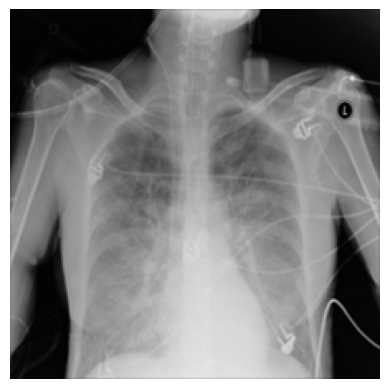

Top predictions:
Lung_Opacity: 0.9700
Infiltration: 0.2899
Normal: 0.2491
Edema: 0.1831
Effusion: 0.1040


In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
from tensorflow.keras.applications.resnet50 import preprocess_input

# Use one image from the test set
sample_path = covid_test.iloc[0]["image_path"]

image = Image.open(sample_path).convert("RGB").resize((224, 224))
image_array = np.array(image)

plt.imshow(image_array)
plt.axis("off")
plt.show()

x = preprocess_input(image_array.astype(np.float32))
x = np.expand_dims(x, axis=0)

predictions = combined_model.predict(x, verbose=0)[0]

print("Top predictions:")
for idx in np.argsort(predictions)[::-1][:5]:
    print(f"{all_classes[idx]}: {predictions[idx]:.4f}")


In [ ]:

import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

# Predict the COVID test images
y_pred = combined_model.predict(val_ds, verbose=1)

# The validation dataset contains COVID images first, then NIH images.
n_covid = len(covid_test)
covid_predictions = y_pred[:n_covid, :4]

# Actual class IDs
y_true = covid_test["class_id"].to_numpy()

# Select the highest-scoring COVID class
y_pred_class = np.argmax(covid_predictions, axis=1)

print("COVID Dataset - Test Results")
print(classification_report(
    y_true,
    y_pred_class,
    labels=[0, 1, 2, 3],
    target_names=covid_classes,
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_true, y_pred_class, labels=[0, 1, 2, 3]))


289/289 ━━━━━━━━━━━━━━━━━━━━ 39s 122ms/step
COVID Dataset - Test Results
                 precision    recall  f1-score   support

         Normal       0.87      0.94      0.91      2038
          COVID       0.95      0.78      0.86       723
   Lung_Opacity       0.87      0.85      0.86      1203
Viral Pneumonia       0.95      0.97      0.96       269

       accuracy                           0.89      4233
      macro avg       0.91      0.88      0.90      4233
   weighted avg       0.89      0.89      0.89      4233

Confusion Matrix:
[[1918   16   92   12]
 [ 103  565   55    0]
 [ 167   15 1020    1]
 [   7    1    1  260]]


In [ ]:

import numpy as np
from sklearn.metrics import classification_report, f1_score

# Predict on NIH validation images only
nih_val_ds = tf.data.Dataset.from_tensor_slices(
    nih_val_fast["image_path"].to_numpy()
)

def load_nih_image(path):
    image = tf.io.decode_image(
        tf.io.read_file(path), channels=3, expand_animations=False
    )
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, (224, 224))
    return preprocess_input(image)

nih_val_ds = nih_val_ds.map(
    load_nih_image, num_parallel_calls=tf.data.AUTOTUNE
).batch(32).prefetch(tf.data.AUTOTUNE)

nih_predictions = combined_model.predict(nih_val_ds, verbose=1)[:, 4:]

nih_actual = nih_val_fast[nih_classes].to_numpy(dtype=int)
nih_predicted = (nih_predictions >= 0.5).astype(int)

print(classification_report(
    nih_actual,
    nih_predicted,
    target_names=nih_classes,
    zero_division=0
))

print("NIH macro F1:", round(
    f1_score(nih_actual, nih_predicted, average="macro", zero_division=0), 4
))
print("NIH micro F1:", round(
    f1_score(nih_actual, nih_predicted, average="micro", zero_division=0), 4
))


157/157 ━━━━━━━━━━━━━━━━━━━━ 21s 108ms/step
                    precision    recall  f1-score   support

       Atelectasis       0.00      0.00      0.00       474
      Cardiomegaly       0.00      0.00      0.00       140
          Effusion       0.48      0.14      0.21       554
      Infiltration       0.67      0.00      0.00       876
              Mass       0.00      0.00      0.00       238
            Nodule       0.00      0.00      0.00       280
         Pneumonia       0.00      0.00      0.00        62
      Pneumothorax       0.33      0.01      0.03       220
     Consolidation       0.00      0.00      0.00       214
             Edema       0.00      0.00      0.00        99
         Emphysema       0.64      0.06      0.11       113
          Fibrosis       0.00      0.00      0.00        86
Pleural_Thickening       0.00      0.00      0.00       123
            Hernia       0.00      0.00      0.00         9

         micro avg       0.49      0.03      0.05     

In [ ]:

from sklearn.metrics import f1_score
import numpy as np

thresholds = np.arange(0.05, 0.51, 0.05)
best_thresholds = []

for i, disease in enumerate(nih_classes):
    best_f1 = -1
    best_t = 0.5

    for t in thresholds:
        pred = (nih_predictions[:, i] >= t).astype(int)
        score = f1_score(
            nih_actual[:, i], pred, zero_division=0
        )

        if score > best_f1:
            best_f1 = score
            best_t = t

    best_thresholds.append(best_t)
    print(f"{disease}: threshold={best_t:.2f}, F1={best_f1:.3f}")

best_thresholds = np.array(best_thresholds)

tuned_predictions = (
    nih_predictions >= best_thresholds.reshape(1, -1)
).astype(int)

print("\nTuned macro F1:",
      round(f1_score(nih_actual, tuned_predictions,
                     average="macro", zero_division=0), 4))

print("Tuned micro F1:",
      round(f1_score(nih_actual, tuned_predictions,
                     average="micro", zero_division=0), 4))

np.save("/content/combined_nih_thresholds.npy", best_thresholds)
print("Thresholds saved.")


Atelectasis: threshold=0.15, F1=0.299
Cardiomegaly: threshold=0.05, F1=0.122
Effusion: threshold=0.20, F1=0.406
Infiltration: threshold=0.10, F1=0.354
Mass: threshold=0.05, F1=0.202
Nodule: threshold=0.10, F1=0.186
Pneumonia: threshold=0.10, F1=0.031
Pneumothorax: threshold=0.10, F1=0.296
Consolidation: threshold=0.05, F1=0.175
Edema: threshold=0.10, F1=0.184
Emphysema: threshold=0.15, F1=0.243
Fibrosis: threshold=0.05, F1=0.000
Pleural_Thickening: threshold=0.05, F1=0.065
Hernia: threshold=0.05, F1=0.000

Tuned macro F1: 0.1831
Tuned micro F1: 0.2834
Thresholds saved.


In [ ]:

import tensorflow as tf
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping

# Unfreeze the last 30 layers of ResNet50
base.trainable = True

for layer in base.layers[:-30]:
    layer.trainable = False

# Keep Batch Normalization layers frozen for stability
for layer in base.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

combined_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss=masked_loss
)

checkpoint = ModelCheckpoint(
    "/content/combined_resnet50_18class_finetuned.keras",
    monitor="val_loss",
    save_best_only=True
)

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history_ft = combined_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=[checkpoint, early_stop]
)

combined_model.save("/content/combined_resnet50_18class_finetuned.keras")
print("Fine-tuning complete. Improved model saved.")


Epoch 1/5
1467/1467 ━━━━━━━━━━━━━━━━━━━━ 238s 152ms/step - loss: 0.1767 - val_loss: 0.1696
Epoch 2/5
1467/1467 ━━━━━━━━━━━━━━━━━━━━ 227s 155ms/step - loss: 0.1603 - val_loss: 0.1617
Epoch 3/5
1467/1467 ━━━━━━━━━━━━━━━━━━━━ 261s 154ms/step - loss: 0.1475 - val_loss: 0.1593
Epoch 4/5
1467/1467 ━━━━━━━━━━━━━━━━━━━━ 262s 154ms/step - loss: 0.1369 - val_loss: 0.1535
Epoch 5/5
1467/1467 ━━━━━━━━━━━━━━━━━━━━ 248s 145ms/step - loss: 0.1272 - val_loss: 0.1546
Fine-tuning complete. Improved model saved.


In [ ]:

import os
from google.colab import files
from tensorflow.keras.models import load_model

best_path = "/content/combined_resnet50_18class_finetuned.keras"

print("Model exists:", os.path.exists(best_path))

if os.path.exists(best_path):
    print("File size:", round(os.path.getsize(best_path) / (1024**2), 2), "MB")
    files.download(best_path)
else:
    print("Model file not found. Check the training output.")


Model exists: True
File size: 201.13 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

from sklearn.metrics import classification_report, f1_score
import numpy as np

# Predict NIH validation images with the fine-tuned combined model
nih_predictions_ft = combined_model.predict(
    nih_val_ds, verbose=1
)[:, 4:]

# Apply the thresholds selected earlier
tuned_predictions_ft = (
    nih_predictions_ft >= best_thresholds.reshape(1, -1)
).astype(int)

print("NIH disease classification results after fine-tuning:")
print(classification_report(
    nih_actual,
    tuned_predictions_ft,
    target_names=nih_classes,
    zero_division=0
))

print("Macro F1:",
      round(f1_score(nih_actual, tuned_predictions_ft,
                     average="macro", zero_division=0), 4))
print("Micro F1:",
      round(f1_score(nih_actual, tuned_predictions_ft,
                     average="micro", zero_division=0), 4))


157/157 ━━━━━━━━━━━━━━━━━━━━ 24s 129ms/step
NIH disease classification results after fine-tuning:
                    precision    recall  f1-score   support

       Atelectasis       0.25      0.48      0.33       474
      Cardiomegaly       0.12      0.29      0.17       140
          Effusion       0.38      0.53      0.44       554
      Infiltration       0.23      0.77      0.36       876
              Mass       0.09      0.63      0.15       238
            Nodule       0.16      0.24      0.20       280
         Pneumonia       0.04      0.02      0.02        62
      Pneumothorax       0.23      0.50      0.31       220
     Consolidation       0.12      0.66      0.20       214
             Edema       0.13      0.44      0.20        99
         Emphysema       0.27      0.25      0.26       113
          Fibrosis       0.09      0.15      0.11        86
Pleural_Thickening       0.06      0.38      0.10       123
            Hernia       0.00      0.00      0.00         9



Saving 00000001_002.png to 00000001_002.png


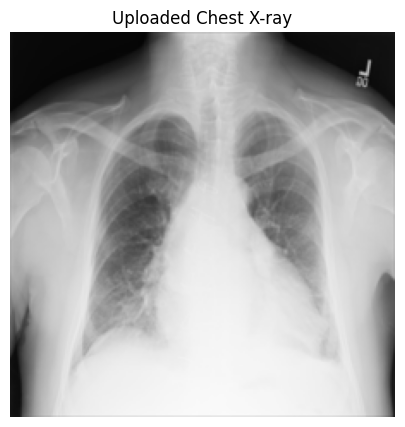

TOP 5 MODEL PREDICTIONS
-----------------------------------
Lung_Opacity         Score: 0.8989
Normal               Score: 0.3226
Emphysema            Score: 0.1485
Atelectasis          Score: 0.1376
Effusion             Score: 0.1169


In [ ]:

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from PIL import Image
from google.colab import files
from tensorflow.keras.applications.resnet50 import preprocess_input

# Upload an X-ray image
uploaded = files.upload()

image_path = next(iter(uploaded))

# Prepare the image
image = Image.open(image_path).convert("RGB")
image_resized = image.resize((224, 224))
image_array = np.array(image_resized, dtype=np.float32)

# Preprocess for ResNet50
x = preprocess_input(image_array.copy())
x = np.expand_dims(x, axis=0)

# Predict using your combined 18-class model
predictions = combined_model.predict(x, verbose=0)[0]

# Display image and top 5 predictions
plt.figure(figsize=(6, 5))
plt.imshow(image)
plt.axis("off")
plt.title("Uploaded Chest X-ray")
plt.show()

top_indices = np.argsort(predictions)[::-1][:5]

print("TOP 5 MODEL PREDICTIONS")
print("-" * 35)

for idx in top_indices:
    print(f"{all_classes[idx]:20s} Score: {predictions[idx]:.4f}")


In [ ]:
print("Image:", sample["Image Index"])
print("Actual NIH labels:", sample["Finding Labels"])

Image: 00000001_002.png
Actual NIH labels: Cardiomegaly|Effusion


In [ ]:
print("Actual labels:", sample["Finding Labels"])
print("Cardiomegaly score:", predictions[all_classes.index("Cardiomegaly")])
print("Effusion score:", predictions[all_classes.index("Effusion")])

Actual labels: Cardiomegaly|Effusion
Cardiomegaly score: 0.09027097
Effusion score: 0.11689292


In [ ]:

import numpy as np
from sklearn.metrics import f1_score

# Search thresholds using the NIH validation data
threshold_grid = np.arange(0.05, 0.81, 0.025)
best_thresholds_ft = []
best_f1_scores = []

for i, disease in enumerate(nih_classes):
    best_f1 = -1
    best_t = 0.5

    for threshold in threshold_grid:
        pred = (nih_predictions_ft[:, i] >= threshold).astype(int)
        score = f1_score(
            nih_actual[:, i], pred, zero_division=0
        )

        if score > best_f1:
            best_f1 = score
            best_t = threshold

    best_thresholds_ft.append(best_t)
    best_f1_scores.append(best_f1)

    print(
        f"{disease:20s} threshold={best_t:.3f} "
        f"F1={best_f1:.3f}"
    )

best_thresholds_ft = np.array(best_thresholds_ft)

# Evaluate on the same validation data used for tuning
tuned_pred_ft = (
    nih_predictions_ft >= best_thresholds_ft.reshape(1, -1)
).astype(int)

print("\nMacro F1:",
      round(f1_score(nih_actual, tuned_pred_ft,
                     average="macro", zero_division=0), 4))
print("Micro F1:",
      round(f1_score(nih_actual, tuned_pred_ft,
                     average="micro", zero_division=0), 4))

np.save("/content/combined_nih_thresholds_finetuned.npy",
        best_thresholds_ft)

print("Fine-tuned thresholds saved.")


Atelectasis          threshold=0.150 F1=0.328
Cardiomegaly         threshold=0.075 F1=0.176
Effusion             threshold=0.200 F1=0.445
Infiltration         threshold=0.150 F1=0.372
Mass                 threshold=0.150 F1=0.231
Nodule               threshold=0.100 F1=0.195
Pneumonia            threshold=0.050 F1=0.033
Pneumothorax         threshold=0.100 F1=0.313
Consolidation        threshold=0.100 F1=0.220
Edema                threshold=0.150 F1=0.212
Emphysema            threshold=0.125 F1=0.285
Fibrosis             threshold=0.050 F1=0.111
Pleural_Thickening   threshold=0.050 F1=0.105
Hernia               threshold=0.050 F1=0.000

Macro F1: 0.2161
Micro F1: 0.2912
Fine-tuned thresholds saved.


In [ ]:

# Use the same image's predictions from earlier
# 'predictions' contains its 18 scores.

nih_scores = predictions[4:]
nih_thresholds = best_thresholds_ft

print("Actual NIH labels:", sample["Finding Labels"])
print("\nPredicted NIH classes using tuned thresholds:")

selected = []

for disease, score, threshold in zip(
    nih_classes, nih_scores, nih_thresholds
):
    if score >= threshold:
        selected.append((disease, float(score), float(threshold)))

if selected:
    for disease, score, threshold in sorted(
        selected, key=lambda x: x[1], reverse=True
    ):
        print(
            f"{disease:20s} score={score:.4f} "
            f"threshold={threshold:.3f}"
        )
else:
    print("No NIH disease score passed its threshold.")


Actual NIH labels: Cardiomegaly|Effusion

Predicted NIH classes using tuned thresholds:
Emphysema            score=0.1485 threshold=0.125
Cardiomegaly         score=0.0903 threshold=0.075
Hernia               score=0.0748 threshold=0.050
Pleural_Thickening   score=0.0586 threshold=0.050
